# Stopword removal and word clouds (Tasks 1.5 and 1.6)

Amharic n-gram language model, NLP Assignment 1.

This notebook (1) downloads the processed data and the team's code, (2) trains the full n-gram model as the *before* baseline, (3) removes 86 stopwords from the training data and recounts the n-grams, and (4) produces the top-10 tables and eight word clouds (n = 1 to 4, before and after).

## 1. Setup: data, code, full model (baseline)

In [1]:
!pip install -q gdown
import gdown
gdown.download_folder(
    "https://drive.google.com/drive/folders/1gnliA5u4iXgDZ2cKBO776K0NXi5PlL33",
    output="/kaggle/working/processed", quiet=False)


Retrieving folder contents


Processing file 1DhcnLXkHDrZRJB4E4ok4OeLvmHvyBFSX .DS_Store
Processing file 1hFDW9wTwxom9Q-LaKbKnupWSKfcToZHL dev.npy
Processing file 1bZ8GyCMQYQowIta4R1mjWl0RK2tXCJ-U stats.json
Processing file 18HipZ-GJ7o1XL6590f7jdxZm1UloeUOB test.npy
Processing file 18xK-8M_u7Pn0yiTh08wsg6YnVx9XNfXu train.npy
Processing file 1brf_NnFPvMUAxgaMBVK4POiWOKxjgDL0 vocab.txt


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1DhcnLXkHDrZRJB4E4ok4OeLvmHvyBFSX
To: /kaggle/working/processed/.DS_Store
100%|██████████| 6.15k/6.15k [00:00<00:00, 5.43MB/s]
Downloading...
From: https://drive.google.com/uc?id=1hFDW9wTwxom9Q-LaKbKnupWSKfcToZHL
To: /kaggle/working/processed/dev.npy
100%|██████████| 34.4M/34.4M [00:00<00:00, 101MB/s] 
Downloading...
From: https://drive.google.com/uc?id=1bZ8GyCMQYQowIta4R1mjWl0RK2tXCJ-U
To: /kaggle/working/processed/stats.json
100%|██████████| 2.76k/2.76k [00:00<00:00, 3.58MB/s]
Downloading...
From: https://drive.google.com/uc?id=18HipZ-GJ7o1XL6590f7jdxZm1UloeUOB
To: /kaggle/working/processed/test.npy
100%|██████████| 34.3M/34.3M [00:00<00:00, 121MB/s] 
Downloading...
From (original): https://drive.google.com/uc?id=18xK-8M_u7Pn0yiTh08wsg6YnVx9XNfXu
From (redirected): https://drive.google.com/uc?id=18xK-8M_u7Pn0yiTh08wsg6YnVx9XNfXu&

['/kaggle/working/processed/.DS_Store',
 '/kaggle/working/processed/dev.npy',
 '/kaggle/working/processed/stats.json',
 '/kaggle/working/processed/test.npy',
 '/kaggle/working/processed/train.npy',
 '/kaggle/working/processed/vocab.txt']

In [3]:
!sha256sum /kaggle/working/processed/train.npy /kaggle/working/processed/vocab.txt

c88588aa527108a3376676c355c212dc79136fcfb879f7a4c54796d070dabb42  /kaggle/working/processed/train.npy
84d8c01602e96fc132bd109d578adaf796b23f1c4aeed696a911b46e7f798e7c  /kaggle/working/processed/vocab.txt


In [2]:
!git clone -b member2-ngram-modeling https://github.com/NaomiMeseret/amharic-ngram-language-model /kaggle/working/code
!ls /kaggle/working/code/src

Cloning into '/kaggle/working/code'...
remote: Enumerating objects: 227, done.
remote: Counting objects: 100% (227/227), done.
remote: Compressing objects: 100% (138/138), done.
remote: Total 227 (delta 85), reused 219 (delta 82), pack-reused 0 (from 0)
Receiving objects: 100% (227/227), 420.86 KiB | 3.54 MiB/s, done.
Resolving deltas: 100% (85/85), done.
ngram_disk.py	preprocess_lib.py  train_ngram_slice.py
ngram_model.py	preprocess.py


In [3]:
import sys, numpy as np
sys.path.insert(0, "/kaggle/working/code")
from src.ngram_model import NGramModel
from src.ngram_disk import DiskBackedNGramTrainer
train = np.load("/kaggle/working/processed/train.npy", mmap_mode="r")
print(train.shape, train.dtype, train[:12])

(68942614,) int32 [    2  8947    47   608 18124     1     1     1   217  1391   374  9216]


In [4]:
script = '''
import sys
sys.path.insert(0, "/kaggle/working/code")
from src.ngram_disk import DiskBackedNGramTrainer
t = DiskBackedNGramTrainer(
    "/kaggle/working/processed/train.npy", "/kaggle/working/processed/vocab.txt",
    "/kaggle/working/ngram_full/work", "/kaggle/working/ngram_full/model",
    max_order=4, scan_chunk_tokens=1_000_000, run_occurrences_limit=2_000_000,
    merge_buffer_size=65_536, max_tokens=None, max_sentence_tokens=100)
result = t.run(resume=False, cleanup_runs=True)
print("DONE", result.report)
'''
open("/kaggle/working/run_train.py", "w").write(script)
import subprocess
log = open("/kaggle/working/train_log.txt", "w")
proc = subprocess.Popen(["python", "/kaggle/working/run_train.py"],
                        cwd="/kaggle/working/code", stdout=log, stderr=subprocess.STDOUT)
print("started, pid", proc.pid)

started, pid 146


## 2. Stopword list and filtered training data

In [8]:
import sys, os, shutil, numpy as np
sys.path.insert(0, "/kaggle/working/code")
from src.preprocess_lib import tokenize

STOPWORDS = """
ነው ላይ ውስጥ ወደ እና ጋር ነበር ግን ደግሞ አንድ ይህ ብቻ እንደ ምን ሁሉ ናቸው ወይም በዚህ ሲሆን
በላይ በኋላ ም መሆኑን እንጂ አይደለም ብሎ እንዲሁም ማለት ሆነ ከዚህ እንዲህ እስከ ሳይሆን መካከል
እንደሆነ ይህን ሆኖ የሚል በፊት ድረስ ያህል በማለት እንዴት አለ ምንም ያለ ስለ እኔ ዛሬ ይችላል
በኩል በጣም ሌሎች ሌላ ብለው ይሆናል በሚል ያለውን የለም ሲል በመሆኑ የሆነ በአንድ ይህንን መሆን
እነዚህ በተለይ ያሉ አሉ ከሆነ መሆኑ ዘንድ ሁሉም ስለዚህ ቢሆንም ተብሎ ይሁን እንኳን ቢሆን
ያሉት አለበት ይገባል እጅግ ይህም አሁንም እኛ
""".split()

vocab = open("/kaggle/working/processed/vocab.txt", encoding="utf-8").read().splitlines()
word_to_id = {w: i for i, w in enumerate(vocab)}

clean, not_in_vocab = [], []
for w in dict.fromkeys(STOPWORDS):          # drops duplicates
    toks = tokenize(w)                       # same normalization as the corpus
    if len(toks) != 1:
        print("skipped:", w, toks); continue
    t = toks[0]
    if word_to_id.get(t, 0) >= 4:
        clean.append(t)
    else:
        not_in_vocab.append(w)
clean = list(dict.fromkeys(clean))
print(len(clean), "stopwords usable;", len(not_in_vocab), "not in vocab:", not_in_vocab)
open("/kaggle/working/stopwords_am.txt", "w", encoding="utf-8").write("\n".join(clean) + "\n")

# --- filter the training IDs ---
BOS, EOS = 2, 3
ids = np.load("/kaggle/working/processed/train.npy")
is_stop = np.zeros(len(vocab), dtype=bool)
is_stop[[word_to_id[w] for w in clean]] = True
assert not is_stop[:4].any()
f = ids[~is_stop[ids]]
bos = np.flatnonzero(f[:-1] == BOS)           # drop sentences that became empty
empty = bos[f[bos + 1] == EOS]
drop = np.zeros(len(f), dtype=bool); drop[empty] = True; drop[empty + 1] = True
f = f[~drop].astype(np.int32)

os.makedirs("/kaggle/working/processed_nostop", exist_ok=True)
np.save("/kaggle/working/processed_nostop/train.npy", f)
shutil.copy("/kaggle/working/processed/vocab.txt", "/kaggle/working/processed_nostop/vocab.txt")
print("IDs:", len(ids), "->", len(f))
print(f"stopword tokens removed: {int(is_stop[ids].sum()):,} ({100*is_stop[ids].mean():.1f}% of all IDs)")
print("sentences:", int((ids == BOS).sum()), "->", int((f == BOS).sum()))

86 stopwords usable; 0 not in vocab: []
IDs: 68942614 -> 61118756
stopword tokens removed: 7,809,464 (11.3% of all IDs)
sentences: 4067589 -> 4060392


## 3. Recount n-grams on the filtered data

In [10]:
script2 = '''
import sys
sys.path.insert(0, "/kaggle/working/code")
from src.ngram_disk import DiskBackedNGramTrainer
t = DiskBackedNGramTrainer(
    "/kaggle/working/processed_nostop/train.npy", "/kaggle/working/processed_nostop/vocab.txt",
    "/kaggle/working/ngram_nostop/work", "/kaggle/working/ngram_nostop/model",
    max_order=4, scan_chunk_tokens=1_000_000, run_occurrences_limit=2_000_000,
    merge_buffer_size=65_536, max_tokens=None, max_sentence_tokens=100)
result = t.run(resume=False, cleanup_runs=True)
print("DONE", result.report)
'''
open("/kaggle/working/run_train_nostop.py", "w").write(script2)
import subprocess
log2 = open("/kaggle/working/train_nostop_log.txt", "w")
proc2 = subprocess.Popen(["python", "/kaggle/working/run_train_nostop.py"],
                         cwd="/kaggle/working/code", stdout=log2, stderr=subprocess.STDOUT)
print("started, pid", proc2.pid)

started, pid 192


## 4. Ethiopic font for the word clouds

In [12]:
!wget -q -O /kaggle/working/NotoSansEthiopic.ttf "https://github.com/notofonts/notofonts.github.io/raw/main/fonts/NotoSansEthiopic/hinted/ttf/NotoSansEthiopic-Regular.ttf"
!ls -l /kaggle/working/NotoSansEthiopic.ttf

-rw-r--r-- 1 root root 376804 Oct 24 11:15 /kaggle/working/NotoSansEthiopic.ttf


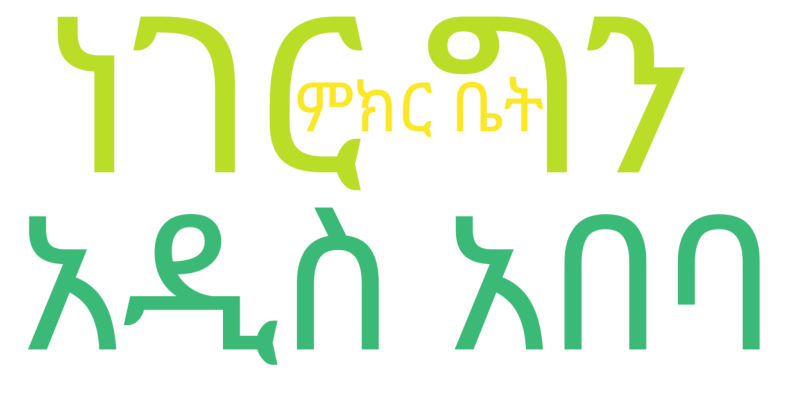

In [13]:
!pip install -q wordcloud
from wordcloud import WordCloud
import matplotlib.pyplot as plt
wc = WordCloud(font_path="/kaggle/working/NotoSansEthiopic.ttf", width=1200, height=600,
               background_color="white", collocations=False).generate_from_frequencies(
    {"አዲስ አበባ": 25000, "ምክር ቤት": 18000, "ነገር ግን": 35000})
plt.figure(figsize=(10, 5)); plt.imshow(wc); plt.axis("off"); plt.show()

## 5. Wait for both models to finish

In [15]:
import os, json
for name in ["ngram_full", "ngram_nostop"]:
    d = f"/kaggle/working/{name}/model"
    print("\n==", name, "| folder exists:", os.path.isdir(d))
    if os.path.isdir(d):
        print(sorted(os.listdir(d)))
        mp = f"{d}/metadata.json"
        if os.path.isfile(mp):
            m = json.load(open(mp, encoding="utf-8"))
            print("sentences:", m["complete_sentences"], "| unique:", m["unique_ngrams_by_order"])
        else:
            print("NO metadata.json -> this model is not finished")
!ps aux | grep run_train | grep -v grep


== ngram_full | folder exists: True
['metadata.json', 'order_1_context_keys.u64', 'order_1_context_totals.u64', 'order_1_counts.u64', 'order_1_keys.u64', 'order_2_context_keys.u64', 'order_2_context_totals.u64', 'order_2_counts.u64', 'order_2_keys.u64', 'order_3_context_keys.u64', 'order_3_context_totals.u64', 'order_3_counts.u64', 'order_3_keys.u64', 'order_4_context_keys.u64', 'order_4_context_totals.u64', 'order_4_counts.u64', 'order_4_keys.u64', 'vocab.txt']
sentences: 4067589 | unique: {'1': 49998, '2': 10265086, '3': 27987839, '4': 38108498}

== ngram_nostop | folder exists: True
['order_1_context_keys.u64', 'order_1_context_totals.u64', 'order_1_counts.u64', 'order_1_keys.u64', 'order_2_context_keys.u64', 'order_2_context_totals.u64', 'order_2_counts.u64', 'order_2_keys.u64', 'order_3_context_keys.u64', 'order_3_context_totals.u64', 'order_3_counts.u64', 'order_3_keys.u64', 'order_4_counts.u64', 'order_4_keys.u64', 'vocab.txt']
NO metadata.json -> this model is not finished
roo

In [16]:
import os, time
p = "/kaggle/working/ngram_nostop/model/metadata.json"
while not os.path.isfile(p):
    time.sleep(15)
print("no-stopword model finished")
!ps aux | grep run_train | grep -v grep

no-stopword model finished


## 6. Top-10 tables and word clouds (before vs after)

In [17]:
import numpy as np, pandas as pd, os, sys
from wordcloud import WordCloud
sys.path.insert(0, "/kaggle/working/code")
from src.ngram_model import NGramModel

OUT = "/kaggle/working/results/stopwords"; os.makedirs(OUT, exist_ok=True)
FONT = "/kaggle/working/NotoSansEthiopic.ttf"
before = NGramModel.load("/kaggle/working/ngram_full/model")
after  = NGramModel.load("/kaggle/working/ngram_nostop/model")

def top_ngrams(model, order, n_top=200, pool=50_000):
    o = model.orders[order]
    counts = np.array(o.counts); keys = np.array(o.keys)
    mm = min(pool, len(counts))
    idx = np.argpartition(counts, -mm)[-mm:] if mm < len(counts) else np.arange(len(counts))
    idx = idx[np.argsort(-counts[idx], kind="stable")]
    vocab = model.vocabulary
    rows = []
    for i in idx:
        k = int(keys[i])
        ids = [(k >> (16 * (order - 1 - j))) & 0xFFFF for j in range(order)]
        toks = [vocab[t] for t in ids]
        if any(t in ("<PAD>", "<UNK>", "<s>", "</s>") or "<NUM>" in t for t in toks):
            continue
        rows.append((" ".join(toks), int(counts[i])))
        if len(rows) == n_top:
            break
    return rows

names = {1: "unigram", 2: "bigram", 3: "trigram", 4: "fourgram"}
for label, model in [("before", before), ("after", after)]:
    for n in range(1, 5):
        rows = top_ngrams(model, n, 200)
        total = model.total_occurrences(n)
        df = pd.DataFrame(rows, columns=["ngram", "count"])
        df["probability"] = df["count"] / total
        df.insert(0, "rank", range(1, len(df) + 1))
        df.to_csv(f"{OUT}/{names[n]}_top200_{label}.csv", index=False, encoding="utf-8-sig")
        print(f"\n=== {label} stopword removal, n={n}, top 10 ===")
        print(df.head(10).to_string(index=False))
        WordCloud(font_path=FONT, width=1600, height=800, background_color="white",
                  max_words=150, collocations=False, prefer_horizontal=1.0
                  ).generate_from_frequencies(dict(rows[:150])
                  ).to_file(f"{OUT}/wordcloud_{names[n]}_{label}.png")
print("\nSaved to", OUT)


=== before stopword removal, n=1, top 10 ===
 rank ngram  count  probability
    1    ነው 921688     0.014207
    2    ላይ 594173     0.009159
    3   ውስጥ 273656     0.004218
    4    ወደ 260934     0.004022
    5    እና 246281     0.003796
    6    ጋር 229818     0.003542
    7   ነበር 217891     0.003359
    8    ግን 214337     0.003304
    9    ጊዜ 193009     0.002975
   10   ነገር 171940     0.002650

=== before stopword removal, n=2, top 10 ===
 rank    ngram  count  probability
    1      አ ም  81929     0.001263
    2   ነገር ግን  35269     0.000544
    3      ዶ ር  28055     0.000432
    4  ብቻ ሳይሆን  25946     0.000400
    5   ማለት ነው  25588     0.000394
    6  አዲስ አበባ  24541     0.000378
    7    ብቻ ነው  19443     0.000300
    8 በአዲስ አበባ  18922     0.000292
    9   ምክር ቤት  18825     0.000290
   10  አለም አቀፍ  16862     0.000260

=== before stopword removal, n=3, top 10 ===
 rank        ngram  count  probability
    1        እ ኤ አ  13138     0.000203
    2      አ ም ኢሳት   7537     0.000116
    3   

In [18]:
!ls /kaggle/working/results/stopwords
!cd /kaggle/working && zip -rq results_stopwords.zip results/stopwords stopwords_am.txt
!ls -lh /kaggle/working/results_stopwords.zip

bigram_top200_after.csv     wordcloud_bigram_after.png
bigram_top200_before.csv    wordcloud_bigram_before.png
fourgram_top200_after.csv   wordcloud_fourgram_after.png
fourgram_top200_before.csv  wordcloud_fourgram_before.png
trigram_top200_after.csv    wordcloud_trigram_after.png
trigram_top200_before.csv   wordcloud_trigram_before.png
unigram_top200_after.csv    wordcloud_unigram_after.png
unigram_top200_before.csv   wordcloud_unigram_before.png
-rw-r--r-- 1 root root 3.6M Oct 24 11:41 /kaggle/working/results_stopwords.zip
